<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [XGBoost](https://github.com/Query-farm/vgi-xgboost)

Train, tune, score and explain gradient-boosted tree models on your tables with plain SQL.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-xgboost/blob/main/notebooks/02_three_questions_about_features.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-xgboost/blob/main/notebooks/README.md)

## Feature importance answers more than one question

Which inputs did a model use, how much does scrambling one input worsen held-out prediction, and how does its average prediction respond when one input is replaced? These are three different measurements. We fit an explicitly synthetic delivery-duration model once and keep a constant control feature visible, including its zero values.

Split gain describes the fitted tree structure. Permutation importance describes a particular evaluation population and scorer. Partial dependence averages model predictions under constructed feature replacements. None establishes a causal effect or an importance ranking valid for another population.

### Choose the replacement axis

`SWEEP_FEATURE` is `distance_km` or `stops`. Changing it affects only the partial-dependence calculation; the 240 source rows, trained model, gain shares and held-out permutations stay fixed. We use 17 requested grid points, but a discrete input can return fewer distinct points.

In [1]:
SWEEP_FEATURE = "distance_km"

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.38":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.38"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, theme, prose, prepare
from IPython.display import display
import os
from tempfile import TemporaryDirectory

check_runtime()
prepare("xgboost")
import xgboost_example as example

example.validate_feature(SWEEP_FEATURE)
model_directory = TemporaryDirectory(prefix="xgboost-example-")
previous_env = {k: os.environ.get(k) for k in ("XGBOOST_MODELS_DIR", "OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS")}
os.environ.update(XGBOOST_MODELS_DIR=model_directory.name, OMP_NUM_THREADS="1", OPENBLAS_NUM_THREADS="1")
session = connect(globals())
theme()

### Use the release and a disposable model registry

The companion verifies public release v0.1.0 and runs its unchanged entry point with its frozen dependency lock. It installs no worker into the notebook kernel. Git/uv and a working XGBoost OpenMP runtime are prerequisites; macOS commonly uses Homebrew `libomp`. The fresh model directory and empty SQL-secret store belong only to this run.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'xgboost' (TYPE vgi, LOCATION 'uv run --no-project --python 3.13 python xgboost_release.py v0.1.0');

,Success


### Give the model a known constant control

The same authored formula combines distance, stops, rush and a deterministic sine residual into minutes. Every fifth ID is held out. `constant_control = 1` is an intentionally unusable splitting feature. An ID, target and split label remain outside the predictors. This is a computation example, not a delivery forecast.

In [5]:
%%sql
CREATE TABLE routes AS
WITH inputs AS (
 SELECT i AS route_id,2.0+(i*17%97)/3.0 AS distance_km,
        (1+i*7%9)::INTEGER AS stops,(i%3=0)::INTEGER AS rush,1.0 AS constant_control
 FROM range(1,241) AS r(i)
)
SELECT *,CASE WHEN route_id%5=0 THEN 'Held out' ELSE 'Training' END AS split,
       12+0.8*distance_km+0.04*distance_km*distance_km+2.5*stops+8*rush+5*sin(route_id*1.73) AS minutes
FROM inputs;
CREATE TABLE fitted AS SELECT * FROM xgboost.main.fit(
 (SELECT route_id,distance_km,stops,rush,constant_control,minutes FROM routes WHERE split='Training' ORDER BY route_id),
 model_name:='feature_questions',estimator:='xgb_regressor',target:='minutes',id:='route_id',
 params:='{"n_estimators":80,"max_depth":2,"learning_rate":0.1,"random_state":0}');
SELECT estimator,task,n_samples,n_features FROM fitted;

,estimator,task,n_samples,n_features
0,xgb_regressor,regression,192,4


### Keep gain and permutation loss on different scales

Gain is the average training-objective improvement at splits using a feature. We divide it by the sum across all four features to show **share of total reported gain**; this is not a share of predictive accuracy. The worker explicitly returns an unused feature with zero gain.

For permutation importance, score is **negative RMSE** on the 48 held-out rows. A positive drop in that score is an increase in RMSE, measured in minutes. Error bars are the standard deviation over ten deterministic shuffles, not confidence intervals. Negative values, if returned, remain negative. The constant feature should produce exactly zero change.

In [6]:
%%sql
CREATE TABLE gain AS SELECT * FROM xgboost.main.feature_importance('feature_questions',importance_type:='gain');
CREATE TABLE permuted AS SELECT * FROM xgboost.main.permutation_importance(
 (SELECT distance_km,stops,rush,constant_control,minutes FROM routes WHERE split='Held out' ORDER BY route_id),
 model_name:='feature_questions',target:='minutes',scoring:='neg_root_mean_squared_error',n_repeats:=10,random_state:=0);
CREATE TABLE comparison AS
SELECT g.feature,g.importance AS raw_gain,
       100*g.importance/nullif(sum(g.importance) OVER (),0) AS gain_share_percent,
       p.importance_mean AS rmse_increase_minutes,p.importance_std AS shuffle_sd_minutes
FROM gain g JOIN permuted p USING(feature);

,Count


In [7]:
%%sql importance <<
SELECT * FROM comparison ORDER BY gain_share_percent DESC,feature;

,feature,raw_gain,gain_share_percent,rmse_increase_minutes,shuffle_sd_minutes
0,distance_km,3845.791504,88.289798,22.260389,2.366374
1,stops,366.327301,8.409963,4.963151,0.483842
2,rush,143.754211,3.300239,0.910410,0.388559
3,constant_control,0.000000,0.000000,0.000000,0.000000


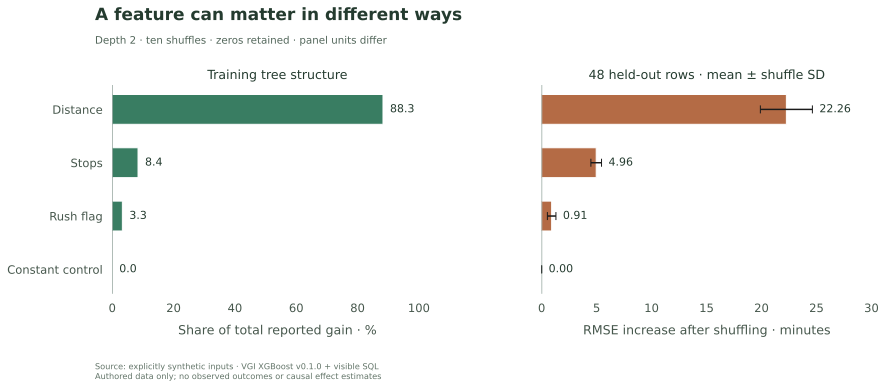

**All 4 features remain visible.** The constant control has 0.0 gain and 0.0 minutes of permutation loss. The other magnitudes answer different questions and must not be compared numerically across panels.

In [8]:
display(importance)
example.feature_questions(importance)
control = importance[importance.feature == "constant_control"].iloc[0]
prose(f"**All {len(importance)} features remain visible.** The constant control has {control.raw_gain:.1f} gain and {control.rmse_increase_minutes:.1f} minutes of permutation loss. The other magnitudes answer different questions and must not be compared numerically across panels.")

### Replace one input and average the predictions

`partial_dependence` uses all 192 training feature rows as the background. At each returned grid value it substitutes the selected input and averages model outputs. Remaining features retain the background population. This construction can combine inputs in ways absent from the data; it does not simulate changing a real driver's route. The horizontal axis takes its values from the worker, not a separately invented range.

In [9]:
%%sql
CREATE TABLE sweep AS SELECT * FROM xgboost.main.partial_dependence(
 (SELECT distance_km,stops,rush,constant_control FROM routes WHERE split='Training' ORDER BY route_id),
 model_name:='feature_questions',feature:='{{ SWEEP_FEATURE }}',grid_resolution:=17);

,Count


In [10]:
%%sql curve <<
SELECT feature_value,partial_dependence FROM sweep ORDER BY feature_value;

,feature_value,partial_dependence
0,3.670000,31.152781
1,5.502917,32.579914
2,7.335833,36.803001
3,9.168750,37.765736
4,11.001667,38.465351
5,12.834583,45.154785
6,14.667500,46.759991
7,16.500417,51.430878
8,18.333333,55.865269
9,20.166250,61.035172


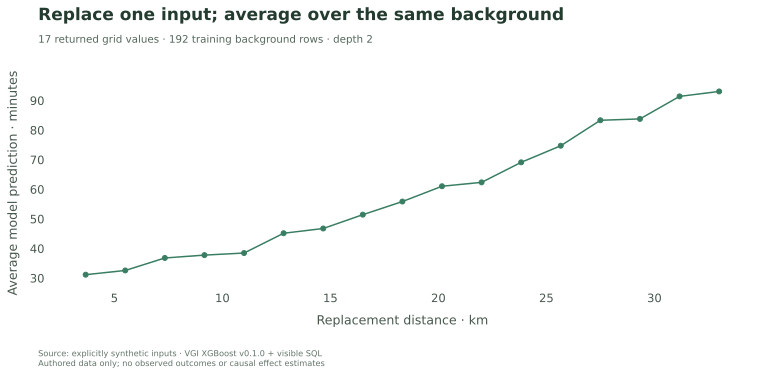

**The worker returned 17 replacement values.** Its averaged prediction spans 31.15–93.06 minutes on this grid. This is a model-response curve using the training background, not an observed duration curve or a causal estimate.

In [11]:
display(curve)
example.partial_curve(curve, SWEEP_FEATURE)
prose(f"**The worker returned {len(curve)} replacement values.** Its averaged prediction spans {curve.partial_dependence.min():.2f}–{curve.partial_dependence.max():.2f} minutes on this grid. This is a model-response curve using the training background, not an observed duration curve or a causal estimate.")

### Check populations and preserve zero importance

The checks verify the 192/48 split, four intended predictors, complete feature accounting, finite returned values and the constant control. They do not require any nonconstant feature to rank first or any held-out error to be small.

In [12]:
%%sql checks <<
SELECT '240 unique source IDs' AS check_name,count(*)=240 AND count(DISTINCT route_id)=240 AS passed FROM routes
UNION ALL SELECT '192 training and 48 held-out',count(*) FILTER(WHERE split='Training')=192 AND count(*) FILTER(WHERE split='Held out')=48 FROM routes
UNION ALL SELECT 'Fit shape',n_samples=192 AND n_features=4 AND task='regression' FROM fitted
UNION ALL SELECT 'Four complete gain rows',count(*)=4 AND count(DISTINCT feature)=4 FROM gain
UNION ALL SELECT 'Four complete permutation rows',count(*)=4 AND count(DISTINCT feature)=4 FROM permuted
UNION ALL SELECT 'No feature lost in join',count(*)=4 FROM comparison
UNION ALL SELECT 'Finite nonnegative gain',bool_and(isfinite(raw_gain) AND raw_gain>=0) FROM comparison
UNION ALL SELECT 'Gain shares sum to 100',abs(sum(gain_share_percent)-100)<1e-9 FROM comparison
UNION ALL SELECT 'Finite permutation mean and SD',bool_and(isfinite(rmse_increase_minutes) AND isfinite(shuffle_sd_minutes) AND shuffle_sd_minutes>=0) FROM comparison
UNION ALL SELECT 'Control remains zero',raw_gain=0 AND rmse_increase_minutes=0 AND shuffle_sd_minutes=0 FROM comparison WHERE feature='constant_control'
UNION ALL SELECT 'Distinct finite sweep coordinates',count(*) BETWEEN 2 AND 17 AND count(*)=count(DISTINCT feature_value) AND bool_and(isfinite(feature_value) AND isfinite(partial_dependence)) FROM sweep
UNION ALL SELECT 'Regression curve has no class',bool_and(class IS NULL) FROM sweep;

In [13]:
display(checks)
assert len(checks) == 12 and checks.passed.fillna(False).all()
prose(f"**All {len(checks)} accounting checks passed.** Zero-valued controls remain in both panels; grid length is validated against actual returned rows.")

,check_name,passed
0,240 unique source IDs,True
1,192 training and 48 held-out,True
2,Fit shape,True
3,Four complete gain rows,True
4,Four complete permutation rows,True
5,No feature lost in join,True
6,Finite nonnegative gain,True
7,Gain shares sum to 100,True
8,Finite permutation mean and SD,True
9,Control remains zero,True


**All 12 accounting checks passed.** Zero-valued controls remain in both panels; grid length is validated against actual returned rows.

### Change one question while keeping the fitted model fixed

Set **`SWEEP_FEATURE = "stops"`**, restart and run all. The gain/permutation table and first figure should be identical. Compare the returned grid population, units and model-response curve. A different slope describes a different input, not a change in the model or in its held-out accuracy.

In [14]:
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
session.close()
model_directory.cleanup()
for key, value in previous_env.items():
    if value is None:
        os.environ.pop(key, None)
    else:
        os.environ[key] = value

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-xgboost](https://github.com/Query-farm/vgi-xgboost)